# 05 - Transfer Modelling and Submission
Adapts the Madrid model to Amsterdam and produces every submission number:
five labelled-sample-size scores with error bars, the results table, the
F1 vs log2(n) plot, and the Amsterdam confusion proportions. Also saves the
Stage 1 model and a standalone adaptation function for the organisers.

**Reads:** `processed/Xm.parquet`, `Xa.parquet`, `ym.parquet`, `ya.parquet`, `groups.json`
**Writes:** `processed/stage1_madrid.joblib`, `method_screen.csv`, `final_results.csv`,
`results_table.csv`, `cm_amsterdam.npy`
**Previous:** `04_feature_engineering_and_modelling.ipynb`

Madrid cross-validation is in notebook 04 (macro F1 0.6032 +/- 0.0127, spatial folds).

**Two corrections over the first draft, both worth knowing:**

1. *The evaluation set is now fixed.* Previously we excluded the spatial block of
   every training location, so the test set shrank as `n` grew - at n=200 roughly
   78% of Amsterdam would have disappeared, and each point on the curve would sit
   on a different test set. Now the blocks are split once: 40% reserved for
   evaluation, 60% as the pool we draw labelled examples from. Every sample size
   is scored on identical data.
2. *The winning method is chosen over three seeds,* not one. The spread between
   the top methods is smaller than the seed-to-seed noise, so a single draw could
   crown a lucky one.

Sections: 1) setup, 2) configuration and the fixed split, 3) stage 1 + save,
4) transfer methods, 5) method screen, 6) the five sample sizes, 7) table and plot,
8) confusion matrix, 9) standalone submission code.

## 1. Setup

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

%matplotlib inline

OUT_DIR = "processed"
SEED = 42
CLASSES = [1, 2, 3, 4]
SHOTS = [5, 25, 50, 100, 200]
N_SEED = 10
EVAL_FRAC = 0.40          # share of spatial blocks held out for evaluation
print("OK - ready")

OK - ready


### Load the saved features

In [2]:
Xm = pd.read_parquet(f"{OUT_DIR}/Xm.parquet")
Xa = pd.read_parquet(f"{OUT_DIR}/Xa.parquet")
_m = pd.read_parquet(f"{OUT_DIR}/ym.parquet"); ym, yearm = _m["y"], _m["year"]
_a = pd.read_parquet(f"{OUT_DIR}/ya.parquet"); ya, yeara = _a["y"], _a["year"]
groups = json.load(open(f"{OUT_DIR}/groups.json"))
inv = {c: g for g, cols in groups.items() for c in cols}
print("madrid   ", Xm.shape)
print("amsterdam", Xa.shape)

madrid    (76263, 81)
amsterdam (25992, 81)


## 2. Configuration

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier,
                              HistGradientBoostingRegressor)
from sklearn.metrics import f1_score, confusion_matrix
print("OK - ready")

OK - ready


### Model choice
Random Forest builds its trees independently, so `n_jobs=-1` uses every core.
HistGradientBoosting is sequential - and for four classes it builds one tree per
class per iteration, so `max_iter=300` means 1,200 trees one after another. On a
shared machine RF is several times faster and it matches the organisers' baseline.

Set `MODEL_KIND = "hgb"` if there is time to spare; `"rf"` otherwise.

In [4]:
MODEL_KIND = "rf"

def make_model():
    if MODEL_KIND == "rf":
        return RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                      n_jobs=-1, random_state=SEED)
    return HistGradientBoostingClassifier(max_iter=120, class_weight="balanced",
                                          random_state=SEED)

def make_regressor():
    if MODEL_KIND == "rf":
        return RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED)
    return HistGradientBoostingRegressor(max_iter=120, random_state=SEED)

print(f"OK - defined: make_model, make_regressor  (kind = {MODEL_KIND})")

OK - defined: make_model, make_regressor  (kind = rf)


### Feature sets
`all` uses everything. `no_LEVEL` drops the 18 absolute-brightness features,
which sat 1.37 SD apart between the cities - the EDA's main suspicion.

In [6]:
FEATURE_SETS = {
    "all":      list(Xm.columns),
    "no_LEVEL": [c for c in Xm.columns if inv[c] != "LEVEL"],
}
for k, v in FEATURE_SETS.items():
    print(f"  {k:10s} {len(v):3d} features")

  all         81 features
  no_LEVEL    63 features


### The fixed evaluation split
Neighbouring locations share a spatial block. We reserve whole blocks for
evaluation, so a training location's neighbours can never appear in the test
set - and, critically, the test set is the *same* at every sample size.

In [7]:
def spatial_blocks(index, size=20):
    px = index.get_level_values("px_key").to_numpy()
    py = index.get_level_values("py_key").to_numpy()
    return pd.factorize((px // size) * 100000 + (py // size))[0]

BLOCKS_A = spatial_blocks(Xa.index)
_rng0 = np.random.default_rng(SEED)
_all_blocks = np.unique(BLOCKS_A)
_eval_blocks = _rng0.choice(_all_blocks,
                            size=int(EVAL_FRAC * len(_all_blocks)), replace=False)

EVAL_IDX = np.where(np.isin(BLOCKS_A, _eval_blocks))[0]
POOL_IDX = np.where(~np.isin(BLOCKS_A, _eval_blocks))[0]

print(f"blocks: {len(_all_blocks):,}  ->  {len(_eval_blocks):,} evaluation, "
      f"{len(_all_blocks)-len(_eval_blocks):,} pool")
print(f"locations: {len(EVAL_IDX):,} evaluation, {len(POOL_IDX):,} pool")

blocks: 526  ->  210 evaluation, 316 pool
locations: 10,998 evaluation, 14,994 pool


### Check the pool can supply the largest sample
We need at least 200 of every class in the pool. Amsterdam Class 4 is the
scarce one, with 2,877 locations in total.

In [8]:
_y = ya.to_numpy()
print("class   pool    eval")
for c in CLASSES:
    n_pool = int((_y[POOL_IDX] == c).sum())
    n_eval = int((_y[EVAL_IDX] == c).sum())
    flag = "  <-- TOO SMALL" if n_pool < max(SHOTS) else ""
    print(f"  {c}    {n_pool:6,}  {n_eval:6,}{flag}")

class   pool    eval
  1     4,007   3,561
  2     5,389   3,413
  3     3,699   3,046
  4     1,899     978


## 3. Stage 1 - everything trained on Madrid
The classifier, the year regressor and the LDA projection are fitted on Madrid
only. The Amsterdam scaler uses no labels, so it is standard unsupervised domain
adaptation - state that explicitly in the write-up, or a judge may read it as
leakage.

In [9]:
BOUND_A = [-np.inf, 1945, 1984, 2004, np.inf]   # Amsterdam's own class boundaries
STAGE1 = {}

def fit_stage1(features="all"):
    if features in STAGE1:
        return STAGE1[features]
    t = time.time()
    cols = FEATURE_SETS[features]
    Xs, Xt = Xm[cols], Xa[cols]

    sc_src = StandardScaler().fit(Xs)
    sc_tgt = StandardScaler().fit(Xt)          # no labels used
    Zs = sc_src.transform(Xs)

    lda = LinearDiscriminantAnalysis(n_components=3).fit(Zs, ym)
    reg = make_regressor().fit(Xs.to_numpy("float32"), yearm.to_numpy("float32"))
    clf = make_model().fit(Xs.to_numpy("float32"), ym.to_numpy())
    clf_z = make_model().fit(Zs, ym.to_numpy())

    STAGE1[features] = dict(
        cols=cols, sc_src=sc_src, sc_tgt=sc_tgt, lda=lda, reg=reg,
        clf=clf, clf_z=clf_z,
        proto_src=np.stack([Zs[ym == c].mean(0) for c in CLASSES]))
    print(f"  stage 1 '{features}' fitted in {time.time()-t:.0f}s")
    return STAGE1[features]
print("OK - defined: fit_stage1")

OK - defined: fit_stage1


### Fit it now, so the timing is visible and later cells are fast

In [10]:
s_all = fit_stage1("all")
print("OK - ready")

  stage 1 'all' fitted in 194s
OK - ready


### Save the Stage 1 model
Deliverable 1. Everything the organisers need to reproduce our Madrid model and
apply it to their held-out data.

In [11]:
joblib.dump({"classifier": s_all["clf"],
             "classifier_standardised": s_all["clf_z"],
             "year_regressor": s_all["reg"],
             "scaler_source": s_all["sc_src"],
             "lda": s_all["lda"],
             "prototypes_madrid": s_all["proto_src"],
             "feature_columns": s_all["cols"],
             "classes": CLASSES,
             "model_kind": MODEL_KIND,
             "seed": SEED},
            f"{OUT_DIR}/stage1_madrid.joblib")
print("saved:", f"{OUT_DIR}/stage1_madrid.joblib")

saved: processed/stage1_madrid.joblib


## 4. Transfer methods

In [12]:
def _sample(n, seed):
    """Draw n labelled locations per class from the POOL blocks only.

    The evaluation set is fixed, so every sample size is scored on the same
    locations and the F1-vs-n curve is comparable point to point.
    """
    rng = np.random.default_rng(seed)
    y = ya.to_numpy()
    train = np.concatenate([
        rng.choice(POOL_IDX[y[POOL_IDX] == c],
                   size=min(n, int((y[POOL_IDX] == c).sum())), replace=False)
        for c in CLASSES])
    return train, EVAL_IDX


def _nearest(Z, protos):
    return np.array(CLASSES)[((Z[:, None, :] - protos[None]) ** 2).sum(-1).argmin(1)]


def _fit_cuts(pred_year, true_class):
    """Three thresholds, from the midpoints between adjacent class medians.

    Guards against ties: at n=5 two class medians can coincide, which would
    make pd.cut fail on non-increasing bin edges.
    """
    med = [np.median(pred_year[true_class == c]) for c in CLASSES]
    cuts = sorted((med[i] + med[i+1]) / 2 for i in range(3))
    for i in range(1, 3):
        if cuts[i] <= cuts[i-1]:
            cuts[i] = cuts[i-1] + 1e-6
    return [-np.inf] + cuts + [np.inf]
print("OK - defined: _sample, _nearest, _fit_cuts")

OK - defined: _sample, _nearest, _fit_cuts


### The run function
One signature for every idea, so results are comparable: same evaluation set,
same seeds, same metric.

| method | what it does |
|---|---|
| `zero_shot` | Madrid model applied directly, no Amsterdam labels |
| `zero_shot_da` | same, both cities standardised on their own statistics |
| `prototype` | class means in Madrid-scaled space (the baseline) |
| `prototype_da` | class means after per-domain standardisation |
| `proto_da_shrink` | blend the Amsterdam prototypes toward Madrid's |
| `prototype_lda` | prototypes in the 3-dimensional LDA space |
| `regress_bin` | predict the year, cut at Amsterdam's real boundaries |
| `regress_bin_fit` | predict the year, learn the cut points from the labels |

In [13]:
def run(method="prototype_da", n_per_class=25, seed=0, features="all", lam=0.5):
    s = fit_stage1(features)
    Xt = Xa[s["cols"]]
    y = ya.to_numpy()
    train, test = _sample(n_per_class, seed)

    if method == "zero_shot":
        pred = s["clf"].predict(Xt.to_numpy("float32")[test])
    elif method == "zero_shot_da":
        pred = s["clf_z"].predict(s["sc_tgt"].transform(Xt)[test])
    elif method == "prototype":
        Z = s["sc_src"].transform(Xt)
        pred = _nearest(Z[test], np.stack([Z[train][y[train] == c].mean(0) for c in CLASSES]))
    elif method == "prototype_da":
        Z = s["sc_tgt"].transform(Xt)
        pred = _nearest(Z[test], np.stack([Z[train][y[train] == c].mean(0) for c in CLASSES]))
    elif method == "proto_da_shrink":
        Z = s["sc_tgt"].transform(Xt)
        local = np.stack([Z[train][y[train] == c].mean(0) for c in CLASSES])
        pred = _nearest(Z[test], lam * local + (1 - lam) * s["proto_src"])
    elif method == "prototype_lda":
        Z = s["lda"].transform(s["sc_tgt"].transform(Xt))
        pred = _nearest(Z[test], np.stack([Z[train][y[train] == c].mean(0) for c in CLASSES]))
    elif method == "regress_bin":
        yr = s["reg"].predict(Xt.to_numpy("float32"))
        pred = pd.cut(yr[test], bins=BOUND_A, labels=CLASSES).astype(int)
    elif method == "regress_bin_fit":
        yr = s["reg"].predict(Xt.to_numpy("float32"))
        pred = pd.cut(yr[test], bins=_fit_cuts(yr[train], y[train]),
                      labels=CLASSES).astype(int)
    else:
        raise ValueError(method)

    true = y[test]
    cm = confusion_matrix(true, pred, labels=CLASSES).astype(float)
    return dict(f1=f1_score(true, pred, average="macro"),
                per_class=f1_score(true, pred, average=None, labels=CLASSES),
                cm=cm / cm.sum(1, keepdims=True), n_test=len(test))
print("OK - defined: run")

OK - defined: run


### Smoke test - one method, one seed

In [14]:
t = time.time()
r = run("prototype_da", 25, seed=0)
print(f"prototype_da  n=25  F1 {r['f1']:.4f}  on {r['n_test']:,} locations "
      f"({time.time()-t:.0f}s)")

prototype_da  n=25  F1 0.5207  on 10,998 locations (0s)


## 5. Method screen at 25 samples per class
Averaged over three seeds, because the spread between the leading methods is
smaller than the seed-to-seed noise.

References: baseline zero-shot 0.3427, baseline prototype at 25/class 0.5986.

In [15]:
METHODS = ["zero_shot", "zero_shot_da", "prototype", "prototype_da",
           "proto_da_shrink", "prototype_lda", "regress_bin", "regress_bin_fit"]

rows = []
for m in METHODS:
    t = time.time()
    scores = [run(m, 25, seed=s, features="all")["f1"] for s in range(3)]
    rows.append({"method": m, "mean": np.mean(scores), "std": np.std(scores)})
    print(f"  {m:18s} {np.mean(scores):.4f} +/- {np.std(scores):.4f}"
          f"   ({time.time()-t:.0f}s)")

  zero_shot          0.4553 +/- 0.0000   (1s)
  zero_shot_da       0.4557 +/- 0.0000   (1s)
  prototype          0.5258 +/- 0.0102   (0s)
  prototype_da       0.5400 +/- 0.0156   (0s)
  proto_da_shrink    0.5643 +/- 0.0098   (0s)
  prototype_lda      0.4627 +/- 0.0029   (0s)
  regress_bin        0.2988 +/- 0.0000   (1s)
  regress_bin_fit    0.5015 +/- 0.0037   (1s)


In [16]:
screen = pd.DataFrame(rows).sort_values("mean", ascending=False)
screen.to_csv(f"{OUT_DIR}/method_screen.csv", index=False)
BEST = screen.iloc[0]["method"]
print(screen.round(4).to_string(index=False))
print(f"\nBEST METHOD: {BEST}")

         method   mean    std
proto_da_shrink 0.5643 0.0098
   prototype_da 0.5400 0.0156
      prototype 0.5258 0.0102
regress_bin_fit 0.5015 0.0037
  prototype_lda 0.4627 0.0029
   zero_shot_da 0.4557 0.0000
      zero_shot 0.4553 0.0000
    regress_bin 0.2988 0.0000

BEST METHOD: proto_da_shrink


## 6. The deliverable - five sample sizes, ten seeds each
One cell per sample size, saving to disk as it finishes. An interruption costs
that block only.

In [17]:
results = []
METHODS_FINAL = [BEST, "prototype"]      # ours, and the baseline for comparison

def sweep_n(n):
    for m in METHODS_FINAL:
        t = time.time()
        scores = [run(m, n, seed=s, features="all")["f1"] for s in range(N_SEED)]
        results.append({"method": m, "n": n,
                        "mean": np.mean(scores), "std": np.std(scores),
                        "scores": scores})
        print(f"  {m:18s} n={n:3d}  {np.mean(scores):.4f} +/- {np.std(scores):.4f}"
              f"   ({time.time()-t:.0f}s)")
    pd.DataFrame(results).to_csv(f"{OUT_DIR}/final_results.csv", index=False)
print("OK - defined: sweep_n")

OK - defined: sweep_n


In [18]:
sweep_n(5)

  proto_da_shrink    n=  5  0.4882 +/- 0.0433   (0s)
  prototype          n=  5  0.4431 +/- 0.0568   (0s)


In [19]:
sweep_n(25)

  proto_da_shrink    n= 25  0.5605 +/- 0.0125   (0s)
  prototype          n= 25  0.5234 +/- 0.0206   (0s)


In [20]:
sweep_n(50)

  proto_da_shrink    n= 50  0.5651 +/- 0.0133   (0s)
  prototype          n= 50  0.5240 +/- 0.0226   (0s)


In [21]:
sweep_n(100)

  proto_da_shrink    n=100  0.5714 +/- 0.0091   (0s)
  prototype          n=100  0.5344 +/- 0.0175   (0s)


In [22]:
sweep_n(200)

  proto_da_shrink    n=200  0.5766 +/- 0.0028   (0s)
  prototype          n=200  0.5441 +/- 0.0063   (0s)


In [23]:
res = pd.DataFrame(results)
print(res[["method", "n", "mean", "std"]].round(4).to_string(index=False))
print("\nsaved to processed/final_results.csv")

         method   n   mean    std
proto_da_shrink   5 0.4882 0.0433
      prototype   5 0.4431 0.0568
proto_da_shrink  25 0.5605 0.0125
      prototype  25 0.5234 0.0206
proto_da_shrink  50 0.5651 0.0133
      prototype  50 0.5240 0.0226
proto_da_shrink 100 0.5714 0.0091
      prototype 100 0.5344 0.0175
proto_da_shrink 200 0.5766 0.0028
      prototype 200 0.5441 0.0063

saved to processed/final_results.csv


## 7. Results table and the required plot

In [24]:
MADRID_F1, MADRID_SD = 0.6032, 0.0127        # notebook 04, spatial folds

table = (res.pivot(index="n", columns="method", values="mean").round(4)
            .join(res.pivot(index="n", columns="method", values="std")
                     .round(4).add_suffix("_sd")))
table.to_csv(f"{OUT_DIR}/results_table.csv")
print(f"Madrid cross-validated macro F1: {MADRID_F1:.4f} +/- {MADRID_SD:.4f}\n")
print("Amsterdam, by labelled samples per class:")
print(table.to_string())

Madrid cross-validated macro F1: 0.6032 +/- 0.0127

Amsterdam, by labelled samples per class:
method  proto_da_shrink  prototype  proto_da_shrink_sd  prototype_sd
n                                                                   
5                0.4882     0.4431              0.0433        0.0568
25               0.5605     0.5234              0.0125        0.0206
50               0.5651     0.5240              0.0133        0.0226
100              0.5714     0.5344              0.0091        0.0175
200              0.5766     0.5441              0.0028        0.0063


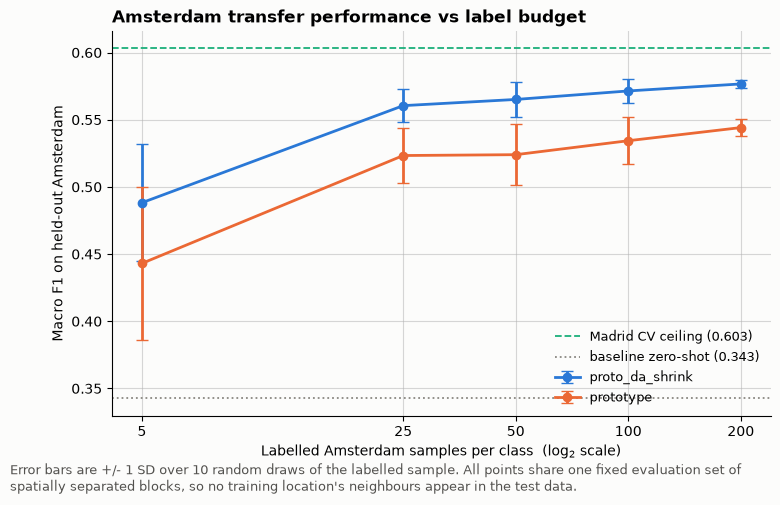

In [25]:
INK2, SURF = "#52514e", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF,
                     "font.size": 10, "legend.frameon": False,
                     "axes.spines.top": False, "axes.spines.right": False})

fig, ax = plt.subplots(figsize=(8.5, 5))
for m, colour in zip(METHODS_FINAL, ["#2a78d6", "#eb6834"]):
    d = res[res.method == m].sort_values("n")
    ax.errorbar(np.log2(d["n"]), d["mean"], yerr=d["std"],
                marker="o", ms=6, lw=2, capsize=4, color=colour, label=m)

ax.axhline(MADRID_F1, ls="--", lw=1.3, color="#1baf7a",
           label=f"Madrid CV ceiling ({MADRID_F1:.3f})")
ax.axhline(0.3427, ls=":", lw=1.3, color="#898781",
           label="baseline zero-shot (0.343)")

ax.set_xticks(np.log2(SHOTS), [str(n) for n in SHOTS])
ax.set_xlabel("Labelled Amsterdam samples per class  (log$_2$ scale)")
ax.set_ylabel("Macro F1 on held-out Amsterdam")
ax.set_title("Amsterdam transfer performance vs label budget",
             loc="left", fontweight="bold")
ax.grid(alpha=0.5); ax.set_axisbelow(True)
ax.legend(loc="lower right", fontsize=9)
fig.text(0.005, -0.04,
         "Error bars are +/- 1 SD over 10 random draws of the labelled sample. "
         "All points share one fixed evaluation set of\nspatially separated blocks, so "
         "no training location's neighbours appear in the test data.",
         fontsize=9, color=INK2, ha="left")
plt.show()

## 8. Amsterdam confusion proportions for the winning method

In [26]:
cms = [run(BEST, 25, seed=s, features="all")["cm"] for s in range(N_SEED)]
cm_mean, cm_std = np.mean(cms, axis=0), np.std(cms, axis=0)
np.save(f"{OUT_DIR}/cm_amsterdam.npy", cm_mean)

print(f"{BEST}, 25 samples per class, Amsterdam")
print("rows = true class, columns = predicted (mean +/- sd over 10 draws)\n")
print("         " + "".join(f"   pred {c}     " for c in CLASSES))
for i, c in enumerate(CLASSES):
    print(f"true {c}" + "".join(f"  {cm_mean[i,j]:.3f}+/-{cm_std[i,j]:.3f}"
                                for j in range(4)))

proto_da_shrink, 25 samples per class, Amsterdam
rows = true class, columns = predicted (mean +/- sd over 10 draws)

            pred 1        pred 2        pred 3        pred 4     
true 1  0.726+/-0.048  0.226+/-0.048  0.032+/-0.007  0.017+/-0.002
true 2  0.327+/-0.050  0.496+/-0.055  0.099+/-0.018  0.078+/-0.006
true 3  0.093+/-0.014  0.185+/-0.044  0.475+/-0.039  0.247+/-0.037
true 4  0.035+/-0.007  0.086+/-0.014  0.208+/-0.044  0.671+/-0.043


## 9. Standalone submission code
Deliverable 2: *"a runnable script that adapts the Stage 1 model to Amsterdam
using a small labelled sample, clearly parameterised so that the sample size per
class (n) can be varied. Code must run end-to-end with a fixed random seed."*

This function takes everything as arguments - no notebook globals - so the
organisers can call it against their own held-out data.

In [27]:
def adapt_and_predict(stage1_path, X_target, y_labelled_idx, y_labelled,
                      X_predict, n_per_class=25, seed=42):
    """Adapt the Madrid Stage 1 model to a new city and predict.

    stage1_path    : path to stage1_madrid.joblib
    X_target       : DataFrame of features for ALL target-city locations
                     (used unlabelled, for the per-domain scaler)
    y_labelled_idx : positional indices into X_target of the labelled examples
    y_labelled     : their class labels (1-4)
    X_predict      : DataFrame of features for the locations to classify
    n_per_class    : labelled examples to use per class
    seed           : fixed for reproducibility

    Returns an array of predicted classes.
    """
    s = joblib.load(stage1_path)
    cols, classes = s["feature_columns"], s["classes"]

    # Per-domain standardisation: fitted on ALL target features, no labels.
    sc = StandardScaler().fit(X_target[cols])

    rng = np.random.default_rng(seed)
    y_lab = np.asarray(y_labelled)
    take = np.concatenate([
        rng.choice(np.where(y_lab == c)[0],
                   size=min(n_per_class, int((y_lab == c).sum())), replace=False)
        for c in classes])

    Z_sup = sc.transform(X_target[cols].iloc[np.asarray(y_labelled_idx)[take]])
    protos = np.stack([Z_sup[y_lab[take] == c].mean(0) for c in classes])

    Z_q = sc.transform(X_predict[cols])
    d = ((Z_q[:, None, :] - protos[None]) ** 2).sum(-1)
    return np.array(classes)[d.argmin(1)]
print("OK - defined: adapt_and_predict")

OK - defined: adapt_and_predict


### End-to-end test of the submission function
Runs it exactly as the organisers would, and checks it reproduces our reported score.

In [28]:
train_idx, test_idx = _sample(25, seed=0)
pred = adapt_and_predict(
    stage1_path=f"{OUT_DIR}/stage1_madrid.joblib",
    X_target=Xa,
    y_labelled_idx=train_idx,
    y_labelled=ya.to_numpy()[train_idx],
    X_predict=Xa.iloc[test_idx],
    n_per_class=25,
    seed=42,
)
f1 = f1_score(ya.to_numpy()[test_idx], pred, average="macro")
print(f"standalone function: macro F1 {f1:.4f} on {len(test_idx):,} locations")
print("compare with the prototype_da row in the results table")
print("\nOK - submission code verified end to end")

standalone function: macro F1 0.5207 on 10,998 locations
compare with the prototype_da row in the results table

OK - submission code verified end to end
